# Chapter 3: Why 89 percent can mean zero: what does accuracy reward?

*Class imbalance against accuracy · also searched as: accuracy paradox, imbalanced classification, base rate*

**Who needs the answer.** Meera Raghavan, CEO of Kalpa Retail, who was told on Monday that the model is about 90 percent accurate and wants to know whether to fund the campaign on that number.

**The questions on the way.** How accurate is a rule that never nudges anyone? Can a useful model score lower accuracy than a useless one? At what base rate does accuracy stop misleading?

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

import numpy as np
# Invented: one hundred Kalpa customers, 11 of whom come back within ninety days (about the bank's 11 percent).
came_back = np.array([1] * 11 + [0] * 89)
print(f"{came_back.sum()} repeaters and {(came_back == 0).sum()} others among {len(came_back)} customers")

11 repeaters and 89 others among 100 customers


## How accurate is the rule that never nudges?

**Predict before you run.** The rule "say no to everyone" is right on how many of the hundred? (a) 11, (b) 50, (c) 89, (d) 100.

say-no-to-everyone: accuracy 89%, repeaters found 0 of 11, recall 0%


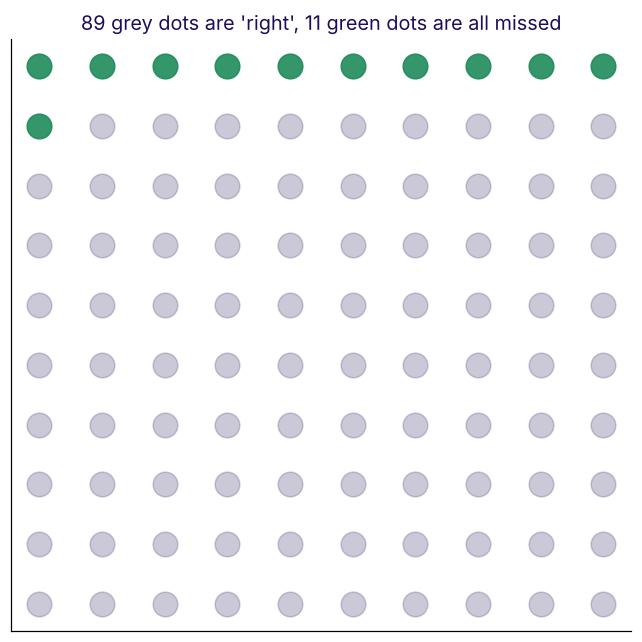

In [2]:
never = np.zeros(100, dtype=int)
acc_never = (never == came_back).mean()
recall_never = (never[came_back == 1] == 1).mean()
print(f"say-no-to-everyone: accuracy {acc_never:.0%}, repeaters found {int(never[came_back == 1].sum())} of 11, recall {recall_never:.0%}")
fig, ax = plt.subplots(figsize=(6, 6))
for i in range(100):
    ax.scatter(i % 10, 9 - i // 10, s=260, color=GREEN if came_back[i] else MUTED, alpha=0.9 if came_back[i] else 0.35)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("89 grey dots are 'right', 11 green dots are all missed", color=INK)
plt.tight_layout(); plt.show()

**What happened.** The answer is (c). The rule is right on the 89 customers who were never coming back and finds none of the 11 who were. Accuracy counts the easy majority as wins, so on an imbalanced outcome it rewards the model that never acts.

## Can a useful model score lower?

Now an invented model that flags 20 customers and finds 8 of the 11 repeaters, with 12 false alarms.

In [3]:
model = np.zeros(100, dtype=int); model[:8] = 1; model[11:23] = 1        # 8 repeaters found, 12 false alarms
acc_model = (model == came_back).mean()
recall_model = model[came_back == 1].mean()
COST_FP, COST_FN = 40, 1200
bill_never = 11 * COST_FN
bill_model = int(((model == 1) & (came_back == 0)).sum()) * COST_FP + int(((model == 0) & (came_back == 1)).sum()) * COST_FN
print(f"the model: accuracy {acc_model:.0%}, recall {recall_model:.0%}, bill Rs {bill_model:,}")
print(f"say-no:    accuracy {acc_never:.0%}, recall {recall_never:.0%}, bill Rs {bill_never:,}")

the model: accuracy 85%, recall 73%, bill Rs 4,080
say-no:    accuracy 89%, recall 0%, bill Rs 13,200


## The trap: "the say-no rule is more accurate, so ship it"

The plausible wrong call ranks the two by accuracy: 89 percent beats 85 percent. Shipping the say-no rule would leave every repeater un-nudged and cost Rs 13,200 in missed margin on these hundred customers, against Rs 4,080 for the model. The check is recall beside accuracy, and the bill beside both. The fix: on an imbalanced outcome, never report accuracy alone.

In [4]:
print("PASS  the say-no rule's accuracy equals the share of non-repeaters" if acc_never == 0.89 else "CHECK accuracy")
print("PASS  the more accurate rule has the larger bill" if acc_never > acc_model and bill_never > bill_model else "CHECK bills")

PASS  the say-no rule's accuracy equals the share of non-repeaters
PASS  the more accurate rule has the larger bill


## When does accuracy stop misleading?

The say-no rule scores the share of the bigger class, so its accuracy is `1 - base rate` while the base rate is under half. The chart plots that free accuracy against the base rate. The closer the outcome is to 50:50, the less a high accuracy can come for free.

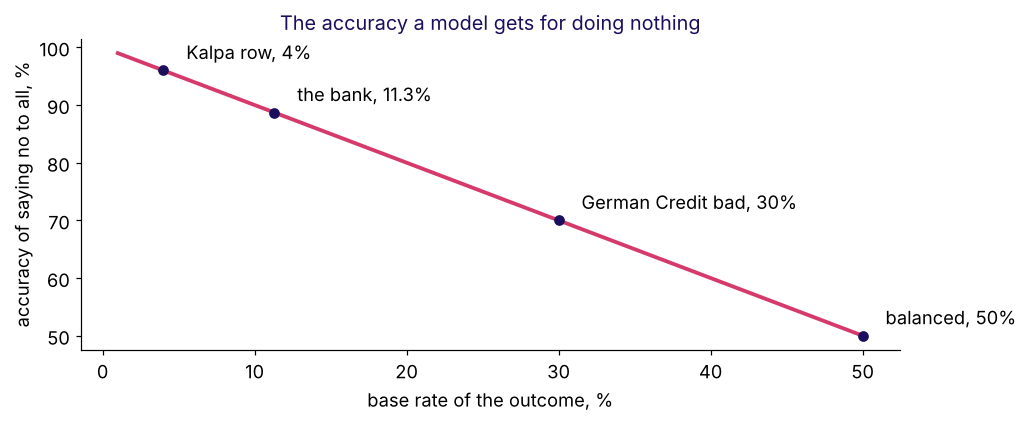

PASS  scikit-learn's accuracy agrees with the count


In [5]:
b = np.linspace(0.01, 0.5, 100)
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(b * 100, (1 - b) * 100, color=ROSE, lw=2.5)
for rate, name in ((0.04, "Kalpa row, 4%"), (0.113, "the bank, 11.3%"), (0.30, "German Credit bad, 30%"), (0.5, "balanced, 50%")):
    ax.scatter(rate * 100, (1 - rate) * 100, color=INK, zorder=5); ax.annotate(name, (rate * 100, (1 - rate) * 100), (rate * 100 + 1.5, (1 - rate) * 100 + 2))
ax.set_xlabel("base rate of the outcome, %"); ax.set_ylabel("accuracy of saying no to all, %")
ax.set_title("The accuracy a model gets for doing nothing", color=INK); plt.tight_layout(); plt.show()
from sklearn.metrics import accuracy_score
print("PASS  scikit-learn's accuracy agrees with the count" if np.isclose(accuracy_score(came_back, model), acc_model) else "CHECK accuracy")

## What did this chapter establish?

| Rule | Accuracy | Repeaters found | Bill |
|---|---|---|---|
| Say no to everyone | 89% | 0 of 11 | Rs 13,200 |
| The invented model | 85% | 8 of 11 | Rs 4,080 |

**The rule.** On an imbalanced outcome, accuracy rewards the model that never acts, so read it only beside the base rate and the recall. It stops lying as the classes approach 50:50 and the two errors cost about the same.

**In the interview.** "Accuracy is 96 percent on a 96 to 4 split. Good model?" Ask for the base rate and the true-positive cell before saying anything else.

Chapter 4 asks which metric to report once the two mistakes carry prices.